In [88]:
# Importação das bibliotecas
import numpy as np
import matplotlib.pyplot as plt
from tifffile import TiffFile

testing_file = "test.tiff"

# Imagens em várias figuras

Total de páginas:  32
Total de séries:  2
Série=0: shape=(13, 1024, 1024)
Série=1: shape=(19, 512, 512)


/tmp/ipykernel_8594/764136948.py:12: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  plt.figure()


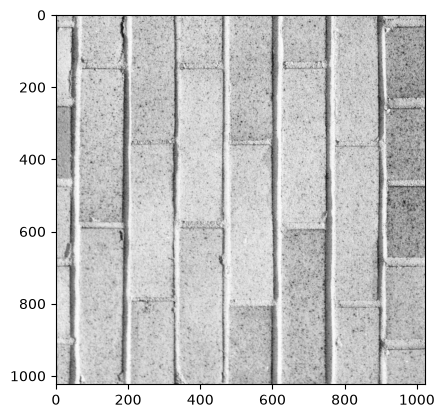

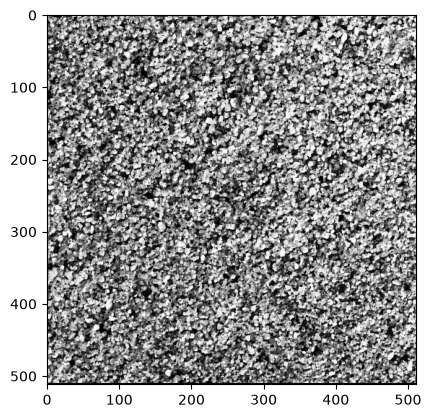

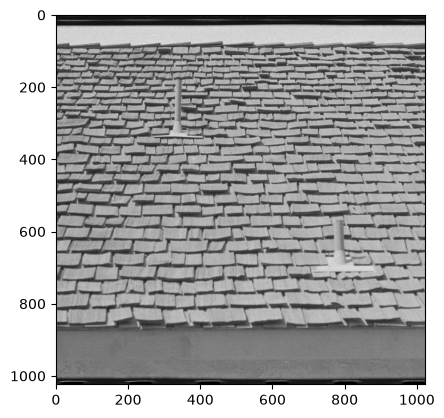

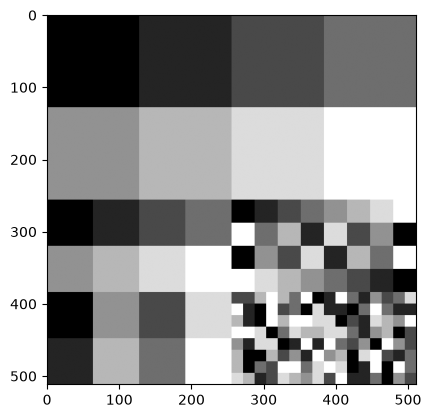

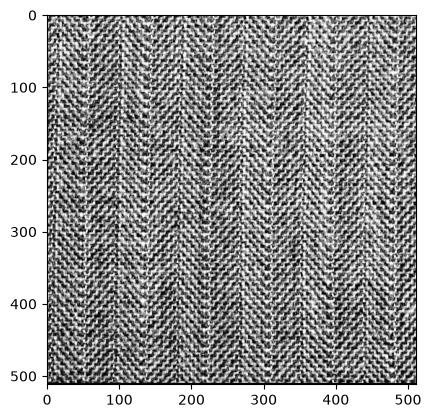

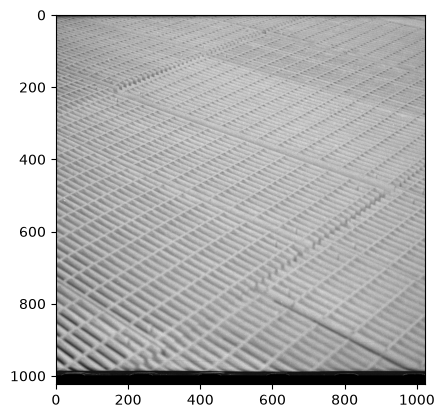

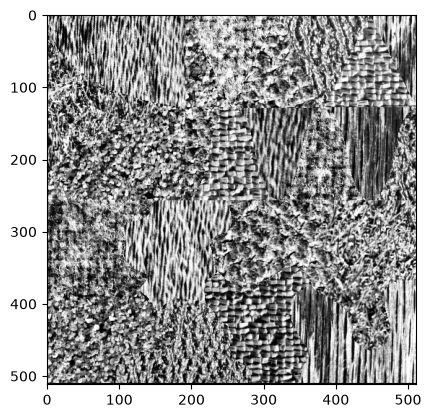

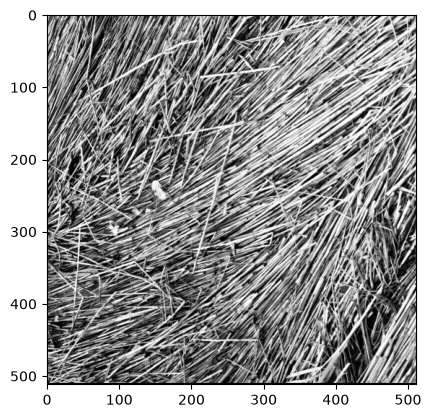

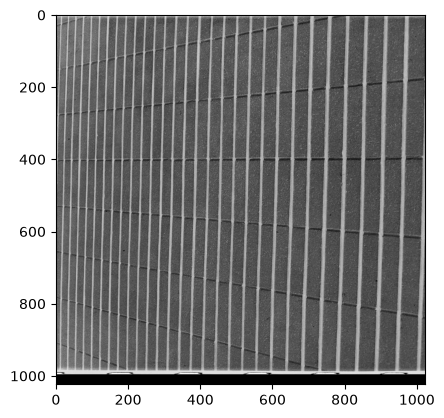

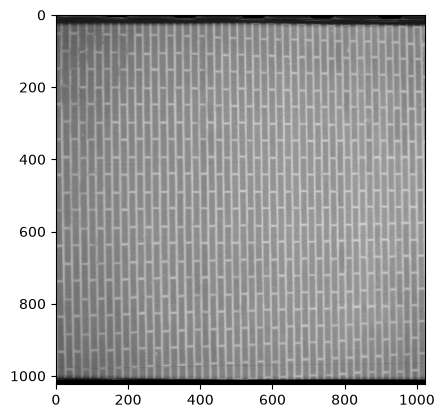

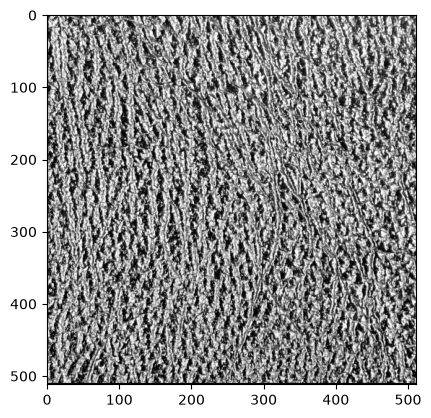

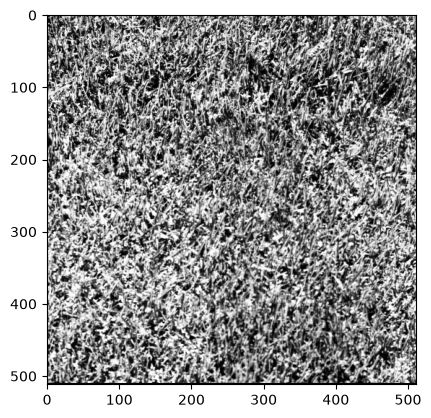

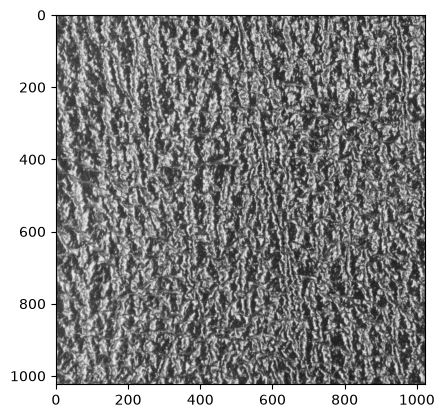

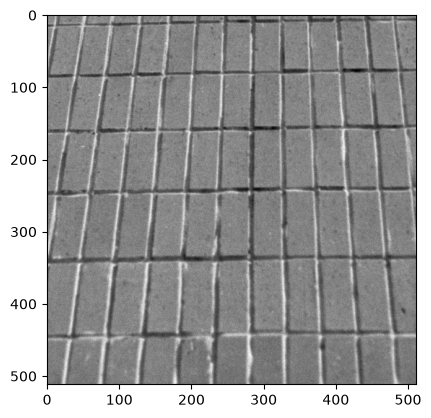

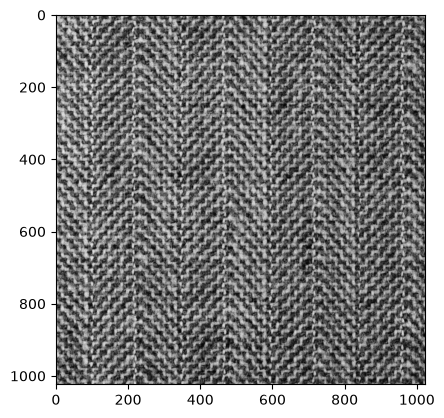

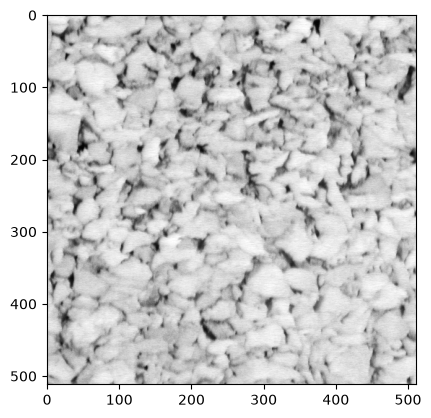

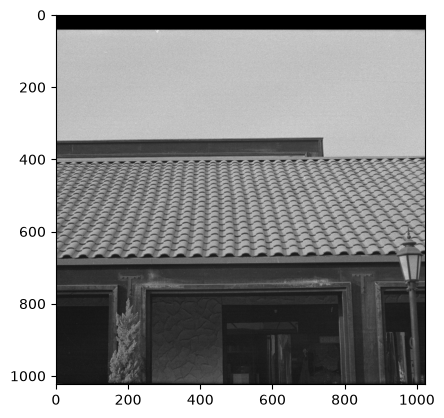

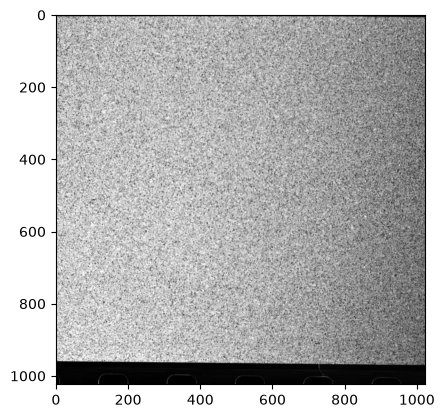

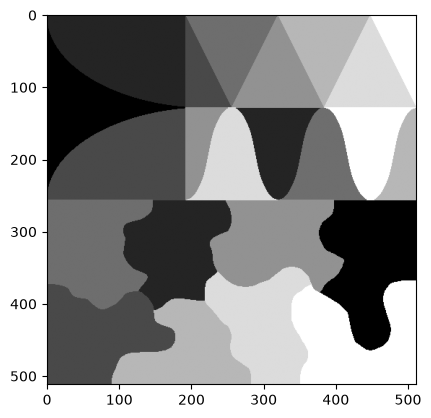

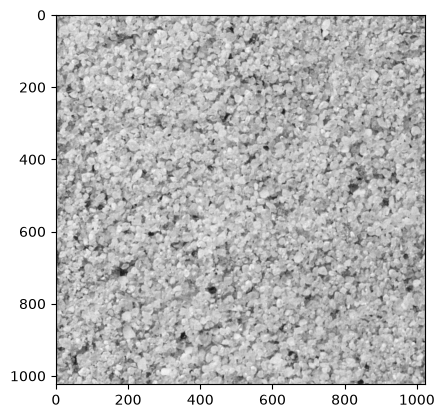

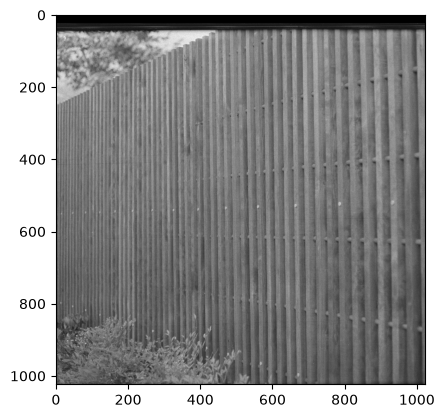

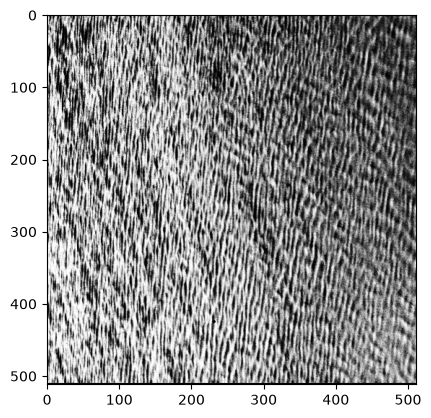

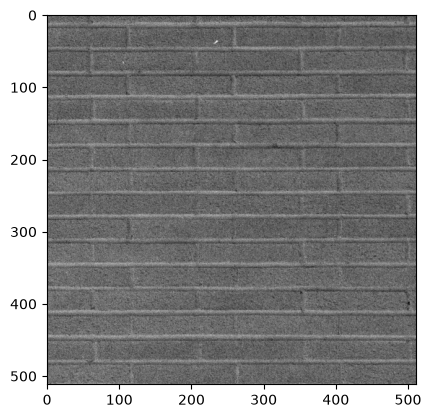

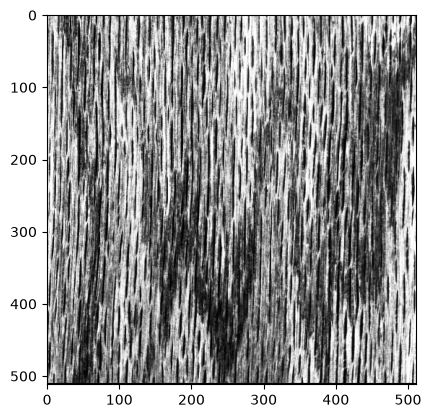

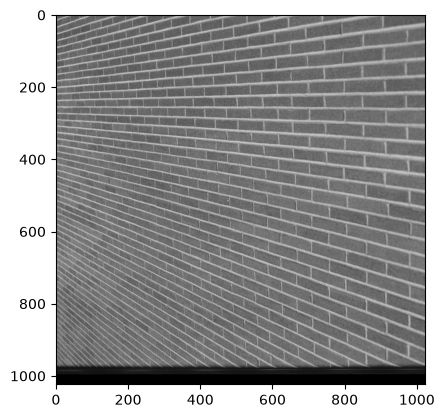

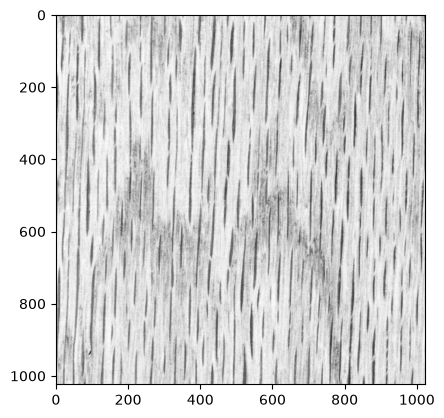

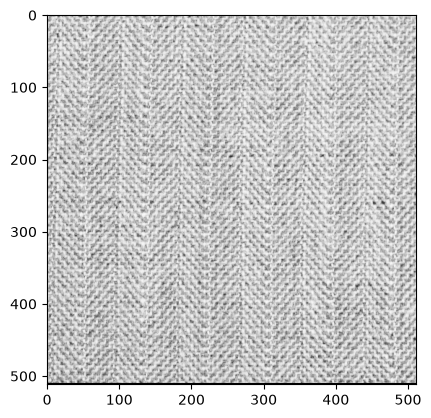

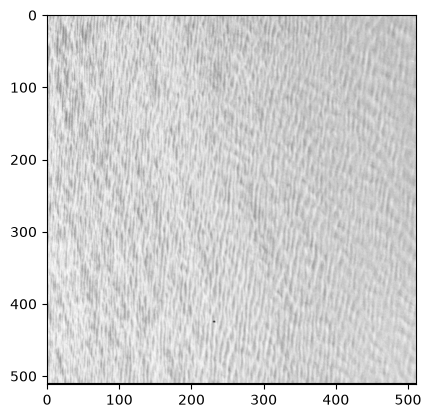

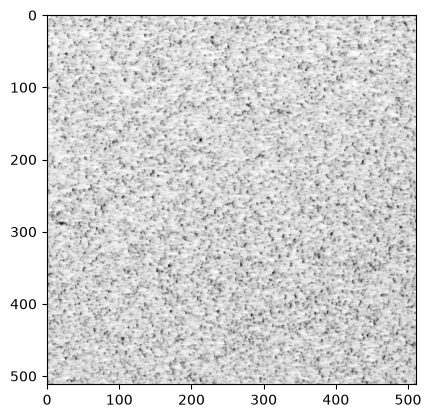

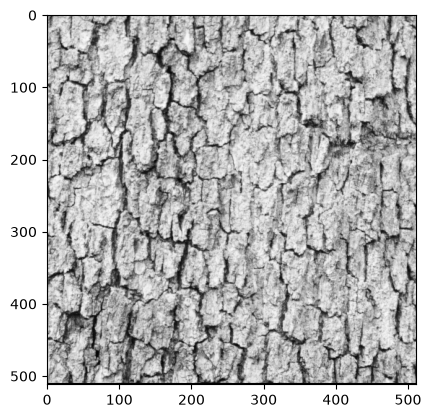

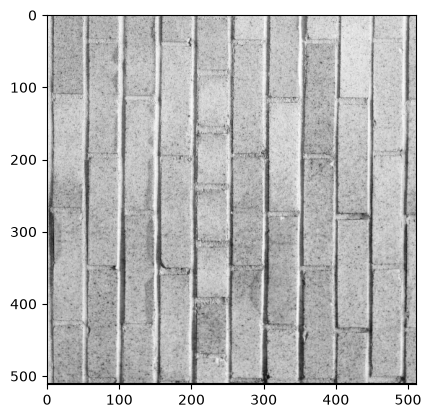

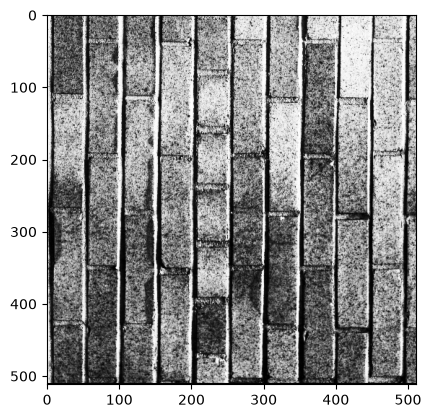

In [92]:
with TiffFile(testing_file) as t:
    print("Total de páginas: ", len(t.pages))
    print("Total de séries: ", len(t.series))

    for i, s in enumerate(t.series):
        print(f"Série={i}: shape={s.shape}")

    images_1024 = [
        p.asarray() for p in t.pages
    ]
    for img in images_1024:
        plt.figure()
        plt.imshow(img, cmap="gray")
plt.show()

# Todas as imagens do test.tiff numa só figura

In [ ]:
with TiffFile(testing_file) as t:
    print("Total de páginas: ", len(t.pages))
    print("Total de séries: ", len(t.series))

    for i, s in enumerate(t.series):
        print(f"Série={i}: shape={s.shape}")

    images_1024 = [
        p.asarray() for p in t.pages
    ]

    rows = len(images_1024) // 4
    cols = len(images_1024) // rows
    figs, axis = plt.subplots(rows, cols, figsize=(17,8), dpi=150)
    axis = axis.flatten()

    for i, img in enumerate(images_1024):
        axis[i].imshow(img, cmap="gray")

plt.show()

Total de páginas:  32
Total de séries:  2
Série=0: shape=(13, 1024, 1024)
Série=1: shape=(19, 512, 512)


# Estudo da Entropia
Como está tudo num único ficheiro pode-se estudar a entropia do ficheiro de várias maneiras.
 - Estudo das páginas num ficheiro (individualmente)
 - Estudo do ficheiro num todo

In [87]:
## Calculo da entropia
def entropia(counts):
    p = counts[counts>0] / counts.sum()
    return -np.sum(p*np.log2(p))
# contar ocorrências de um array. Devolve uma matriz de valores únicos e a matriz original com os valores de referência aos valores únicos
# Exemplo: "abbaccd" -> (["a", "b", "c", d], [0, 1, 1, 0, 2, 2, 3])
def countOcurrences(arr):
    return np.unique(arr, return_inverse=True, axis=0)